# Predicting Goodreads romance shelves from the book description

This is the written report for CSE 258 Assignment 2. It is meant to be read while the presentation plays. The modeling code has already been run on the full romance metadata. This notebook does not refit those models. It records the task, the data, the selected model, the evaluation, and the related work.

The local file used for the data checks is `data/goodreads_books_romance.json.gz`. Its sha256 is `19006689989a90d1b83ede16c6ef2338f65f8f432956515d7c6489fe7ac94d01`, the same digest stored in `reports/full/data_audit.json`. Test metrics are copied from `reports/full/test_results.csv` and the per-shelf table.


## 1. Predictive task

**Task.** Given only a book's description, predict which of 15 reader shelves apply. A book may have several of these shelves, or none. The shelves are reader tags such as `m-m`, `historical-romance`, and `manga`, not a hand-built genre ontology.

**Inputs and outputs.** The input is the description string. The output is 15 binary labels. A shelf is positive when it accounts for at least 10% of that book's content-shelf votes, after status and format shelves such as `to-read`, `ebook`, and the generic tags `romance` and `fiction` are removed. A book also needs at least 10 remaining shelf votes. The 15 names are chosen from the training books only, in the order stored in `reports/full/selection.json`.

**How the model is judged.** The split keeps every edition of a work on the same side: 191,692 training books, 47,687 validation books, and 60,410 test books. Validation chooses the model and the thresholds. The test set is used once, after that choice. The reported scores are micro-F1, macro-F1, macro ROC-AUC, and average precision. Accuracy is not the headline metric, because 65.6% of eligible books have none of the 15 labels. A classifier that predicts all negatives would look accurate and would score zero F1.

**Baselines.** Two baselines use no learned weights. The label prior predicts a shelf only when at least half of training books have it. None do, so its F1 is zero. The keyword baseline predicts a shelf when the shelf name appears in the description. The learned comparison is a word-only logistic regression with the same training split. A separate 12-label run merges three alias pairs. That run is a different target and is not mixed into the 15-label table.

**Whether a prediction is valid.** Shelf votes are a noisy proxy, not a checked genre label. Validity is checked in three ways: the test books were not used to pick the model, editions of one work are not split across train and test, and ten high-confidence mistakes were read against the publisher description and the raw shelf counts (`reports/manual_error_analysis.csv`).


## 2. Data, collection, and cleaning

**Source.** The file is the romance subset of the UCSD Goodreads crawl (Wan and McAuley, 2018; Wan et al., 2019), collected in late 2017 from public Goodreads shelves. The authors ask that it be used for academic work only and not redistributed, so `data/` stays out of Git. The romance file is book metadata only: no users, no reviews.

**What the task uses.** Three fields: `description` is the only model input, `popular_shelves` builds the targets, and `work_id` groups editions for the split. Everything else (year, ratings, language, pages, publisher, `similar_books`) is described below but never reaches the classifier.

**Cleaning, in order.** `scripts/eda_romance.py` re-reads the raw file with the same rules as `modeling/core.py`, and its counts match `reports/full/data_audit.json` exactly.

1. Drop books whose description is empty after stripping whitespace.
2. Remove 27 shelves that describe reading status, format, or the whole file (`to-read`, `owned`, `kindle`, `romance`, `fiction`, ...). What remains are *content votes*.
3. Drop books with fewer than 10 content votes, because a 10% share of a handful of votes is not a label.
4. A shelf is positive when it holds at least 10% of a book's content votes. The 15 shelves are the most frequent positives in the training split only.
5. Split by `work_id` into train / validation / test so editions of one book never straddle splits.

The text itself is not rewritten: no stemming, HTML stripping, or language filtering. The TF-IDF vectorizer lowercases and tokenizes it.

Raw books                         335,449
With a description                304,837
>= 10 content votes (eligible)    299,789
Train split                       191,692
Validation split                   47,687
Test split                         60,410
dropped: empty description         30,612
dropped: < 10 content votes         5,048


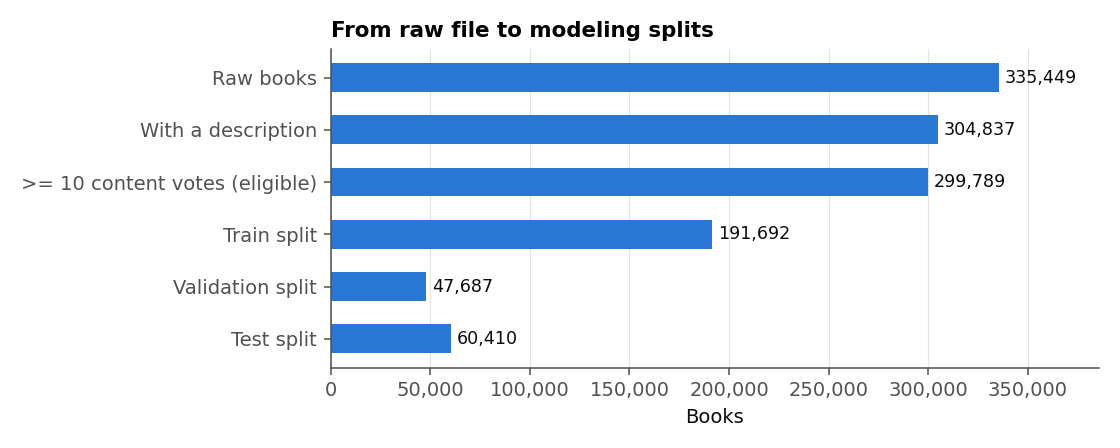

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from scipy.stats import spearmanr

pd.set_option('display.width', 120)
EDA = 'reports/eda/'
stats = json.load(open(EDA + 'eda_stats.json'))
for step, n in stats['flow'].items():
    print(f'{step:32s}{n:>9,}')
print(f"{'dropped: empty description':32s}{stats['dropped_no_description']:>9,}")
print(f"{'dropped: < 10 content votes':32s}{stats['dropped_fewer_than_10_votes']:>9,}")
display(Image(EDA + 'sample_flow.png'))

### 2.1 The descriptions

A description is short publisher copy: median 147 words, 90% under 241. `manga` volumes are the exception, with a median of 69 words, because their blurbs are often a sentence or two. 2,378 eligible descriptions have under 20 words, which gives the model very little to work with.

The text is not all English. Only 61% of eligible books carry an English language code; 28% have no code at all, and Italian, Spanish and Indonesian editions each run to thousands of books. The model sees those descriptions as they are, so a shelf that is common in one language can partly be learned as "this language".

Editions repeat text. 99,319 eligible books share an exact description with another book, but only 1,419 of them share it across *different* works. Almost all duplication is editions of the same work, which is exactly what the `work_id` split keeps on one side. 1,013 books still share text across splits; the modeling diagnostic removes the 279 of those in test and macro-F1 moves from 0.4843 to 0.4842.

description words  p10 74  median 147  p90 241  p99 443  max 3,943
descriptions under 20 words: 2,378
descriptions with HTML tags: 51
English language codes: 61.1%   empty code: 28.3%
top codes: eng 148,852, (empty) 84,818, en-US 17,554, en-GB 13,729, ita 5,107, spa 4,876, ind 3,625, en-CA 3,165
books sharing an exact description: 99,319 (42,381 distinct texts)
  ...shared across different works: 1,419
  ...shared across splits:          1,013
               shelf  median_words
          (no label)         146.0
                 m-m         160.0
  historical-romance         143.0
          paranormal         154.0
          historical         145.0
contemporary-romance         150.0
  paranormal-romance         147.0
        contemporary         146.0
           chick-lit         145.0
           new-adult         170.0
         young-adult         139.0
             erotica         146.0
                bdsm         164.0
               manga          69.0
   romantic-suspense       

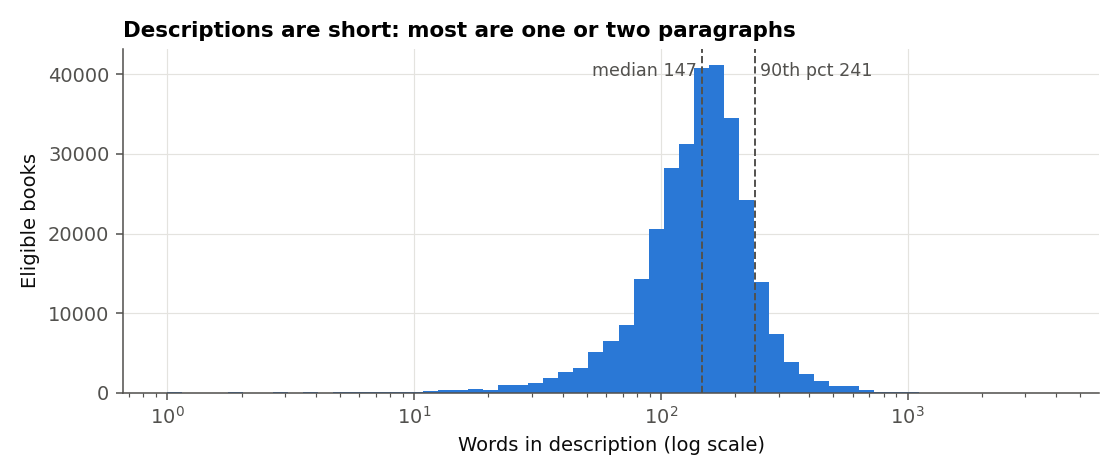

In [1]:
d = stats['description_words']
print('description words  p10 {p10:.0f}  median {median:.0f}  p90 {p90:.0f}  p99 {p99:.0f}  max {max:,}'.format(**d))
print('descriptions under 20 words:', f"{d['under_20_words']:,}")
print('descriptions with HTML tags:', stats['descriptions_with_html_tags'])
lang = stats['language_eligible']
print(f"English language codes: {lang['english_codes_share']:.1%}   empty code: {lang['empty_share']:.1%}")
print('top codes:', ', '.join(f'{k} {v:,}' for k, v in lang['top'].items()))
dup = stats['duplicate_descriptions']
print(f"books sharing an exact description: {dup['books_sharing_exact_text']:,}"
      f" ({dup['distinct_shared_texts']:,} distinct texts)")
print(f"  ...shared across different works: {dup['books_whose_text_spans_several_works']:,}")
print(f"  ...shared across splits:          {dup['books_whose_text_crosses_splits']:,}")
words = pd.read_csv(EDA + 'description_words_by_label.csv')
print(words.to_string(index=False))
display(Image(EDA + 'description_lengths.png'))

### 2.2 The targets

Each label is built from reader votes, and the vote counts vary a lot: the median book has 137 content votes, but 10% have fewer than 30, where three readers can decide a 10% share.

The labels are sparse. 65.6% of eligible books have none of the 15 shelves, and 97.1% of all book-shelf cells are negative, so predicting "no" everywhere is 97.1% accurate and has F1 zero. That is why the evaluation uses F1, AUC and AP rather than accuracy. Prevalence runs from 6.8% (`m-m`) down to 1.1% (`fantasy`) and is close across the three splits, so the split itself does not shift the label mix. For about half the books (51.9%), the single most-voted content shelf is one of the 15; the rest are dominated by shelves like `series` or less common genres.

content votes per book: p10 30, median 137, p90 1244
labels per book: {'0': 196649, '1': 75513, '2': 26982, '3': 636, '4': 9}
books with none of the 15: 65.6%
book-shelf cells that are negative: 97.1%
most-voted content shelf is one of the 15: 51.9%
               shelf  eligible_positives train_prevalence validation_prevalence test_prevalence
                 m-m               19926            6.77%                 6.41%           6.44%
  historical-romance               19344            6.52%                 6.53%           6.19%
          paranormal               13190            4.49%                 4.19%           4.30%
          historical               11618            3.91%                 3.80%           3.82%
contemporary-romance                8268            2.82%                 2.55%           2.71%
  paranormal-romance                7800            2.68%                 2.46%           2.47%
        contemporary                8366            2.68%                 2.94

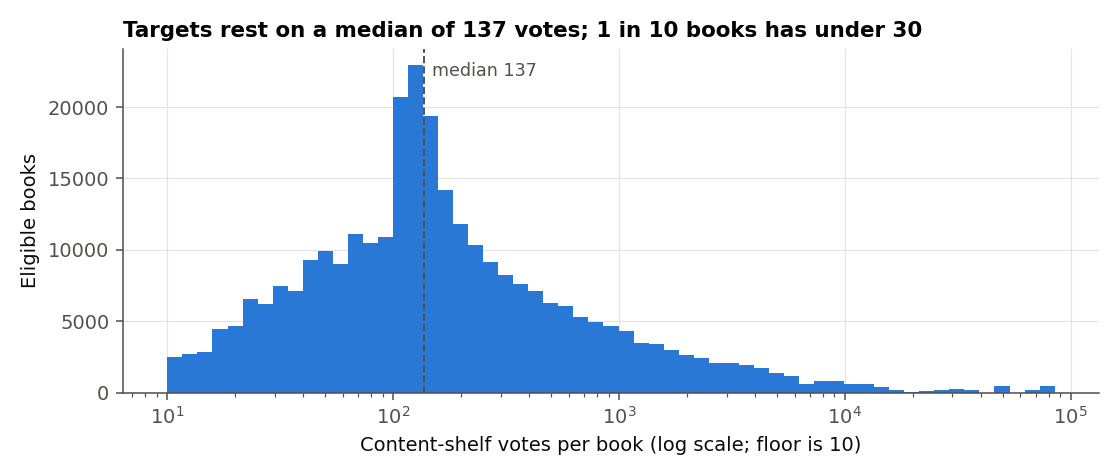

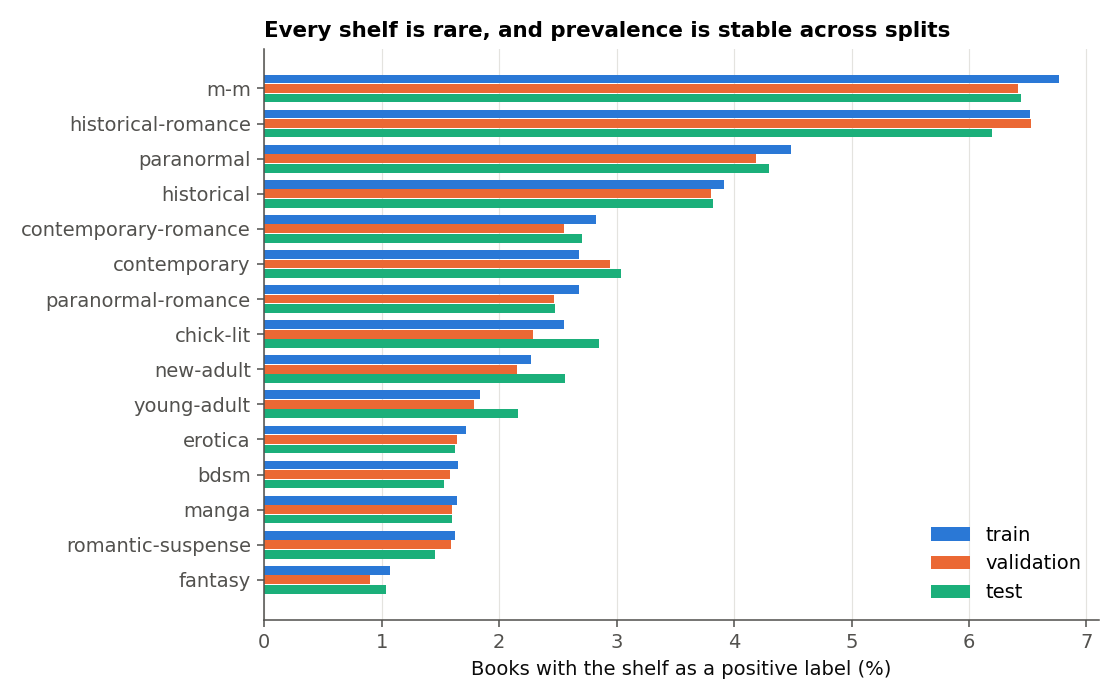

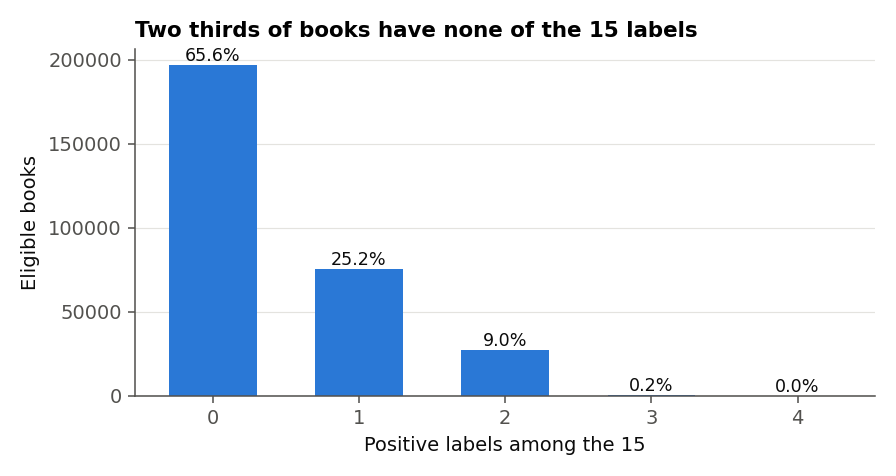

In [1]:
v = stats['content_votes']
print(f"content votes per book: p10 {v['p10']:.0f}, median {v['median']:.0f}, p90 {v['p90']:.0f}")
print('labels per book:', stats['labels_per_book'])
print(f"books with none of the 15: {stats['zero_label_fraction']:.1%}")
print(f"book-shelf cells that are negative: {stats['label_level_negative_rate']:.1%}")
print(f"most-voted content shelf is one of the 15: {stats['top_shelf_is_one_of_15']:.1%}")
support = pd.read_csv(EDA + 'label_support_by_split.csv')
cols = ['shelf', 'eligible_positives', 'train_prevalence', 'validation_prevalence', 'test_prevalence']
print(support[cols].to_string(index=False, formatters={
    c: '{:.2%}'.format for c in cols if c.endswith('prevalence')}))
display(Image(EDA + 'content_votes.png'))
display(Image(EDA + 'label_support.png'))
display(Image(EDA + 'labels_per_book.png'))

### 2.3 Overlapping shelves

The 15 labels are not 15 separate genres. Readers use a generic and a "-romance" spelling side by side: 86% of training books tagged `historical` are also tagged `historical-romance`, and 79% of `paranormal-romance` books are also `paranormal`. The contemporary pair overlaps less (about 0.43 each way), and `contemporary` also absorbs 37% of `young-adult`. `erotica`, `bdsm` and `m-m` form a looser second cluster: a quarter of `erotica` books are also `bdsm`, and a quarter of `bdsm` books are also `m-m`. This is why the modeling section also reports a separate 12-label run that merges the three alias pairs.

P(column | row), training books, largest off-diagonal values
  P(historical-romance | historical) = 0.86
  P(paranormal | paranormal-romance) = 0.79
  P(historical | historical-romance) = 0.52
  P(paranormal-romance | paranormal) = 0.47
  P(contemporary-romance | contemporary) = 0.44
  P(contemporary | contemporary-romance) = 0.42
  P(contemporary | young-adult) = 0.37
  P(erotica | bdsm) = 0.26


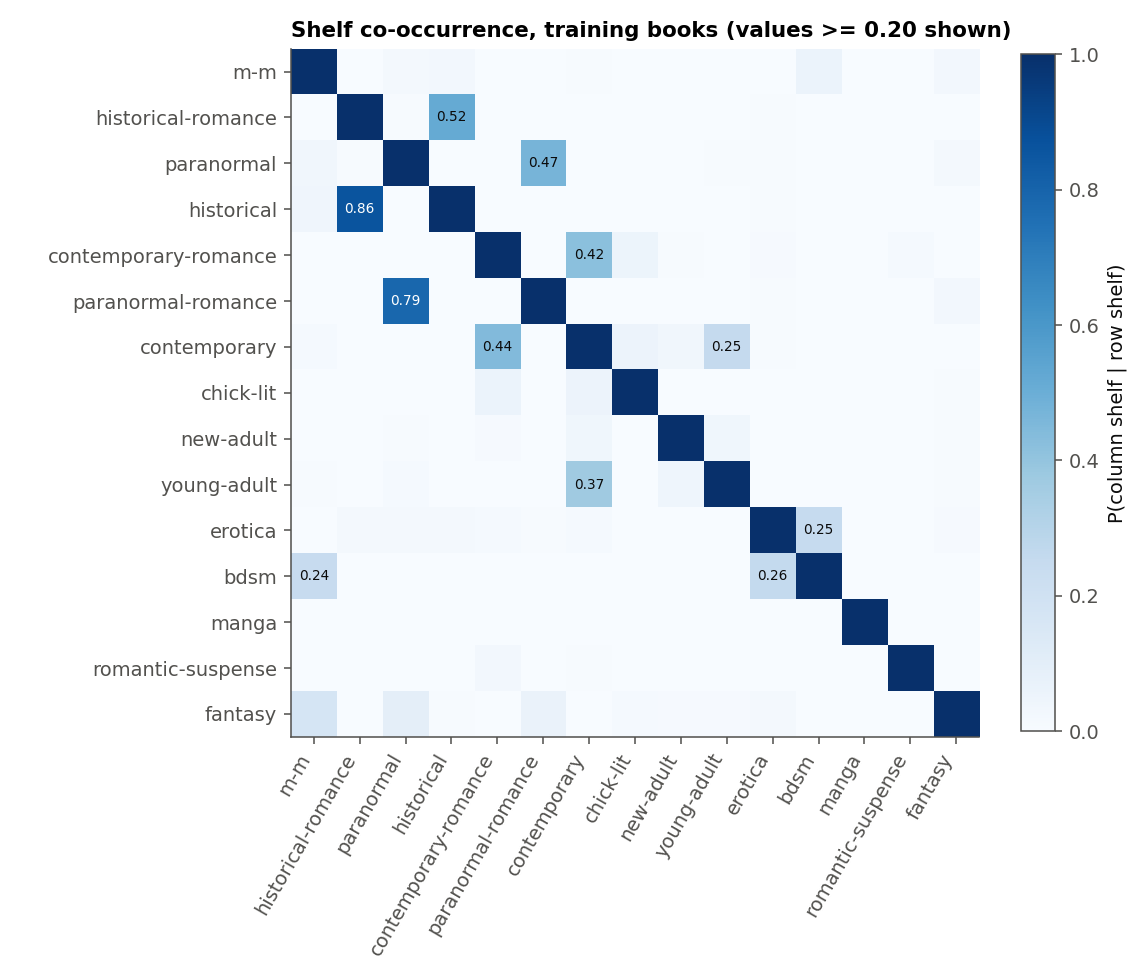

In [1]:
co = pd.read_csv(EDA + 'label_cooccurrence_train.csv', index_col=0)
pairs = [(a, b, co.loc[a, b]) for a in co.index for b in co.columns if a != b]
top = sorted(pairs, key=lambda p: -p[2])[:8]
print('P(column | row), training books, largest off-diagonal values')
for a, b, p in top:
    print(f'  P({b} | {a}) = {p:.2f}')
display(Image(EDA + 'label_cooccurrence.png'))

### 2.4 How noisy is each label?

The 10% rule draws a hard line through a continuous vote share. For each shelf, the chart below divides the number of books just *under* the line (5-10% of votes) by the number at or above it. For `manga` the ratio is 0.02: readers either call a book manga or they don't. For `contemporary` it is 5.3, so for every positive there are five near-identical books labeled negative. `contemporary-romance` (3.7), `fantasy` (3.4) and `erotica` (2.8) follow.

Those are the shelves the model does worst on. Across the 15 shelves, this ratio has a Spearman correlation of -0.84 with the selected model's test F1, while the number of test positives barely relates to F1 (rho +0.26). The weak shelves are not weak because they are small. Their labels are the least decisive, and the evaluation's error review found the same thing book by book.

The second chart explains the keyword baseline. A shelf name rarely appears in the description of its own positives: 36% for `bdsm`, around 10% for `m-m`, `paranormal` and `new-adult`, and 1-3% for `historical-romance`, `contemporary`, `chick-lit` and `young-adult`. A literal match cannot do much, and its test macro-F1 of 0.106 shows it. A learned model has to rely on indirect cues: pronouns, settings, names.

               shelf  share_5_to_10pct  share_at_least_10pct  near_miss_to_positive  positive_rate    f1
               manga               118                  4864                  0.024          0.039 0.880
                 m-m              8777                 19926                  0.440          0.093 0.683
  historical-romance              9466                 19344                  0.489          0.031 0.697
         young-adult              4596                  5672                  0.810          0.021 0.462
           chick-lit              7969                  7708                  1.034          0.013 0.467
          historical             13263                 11618                  1.142          0.046 0.541
                bdsm              5678                  4833                  1.175          0.363 0.566
           new-adult              8838                  6922                  1.277          0.128 0.394
   romantic-suspense              6323                 

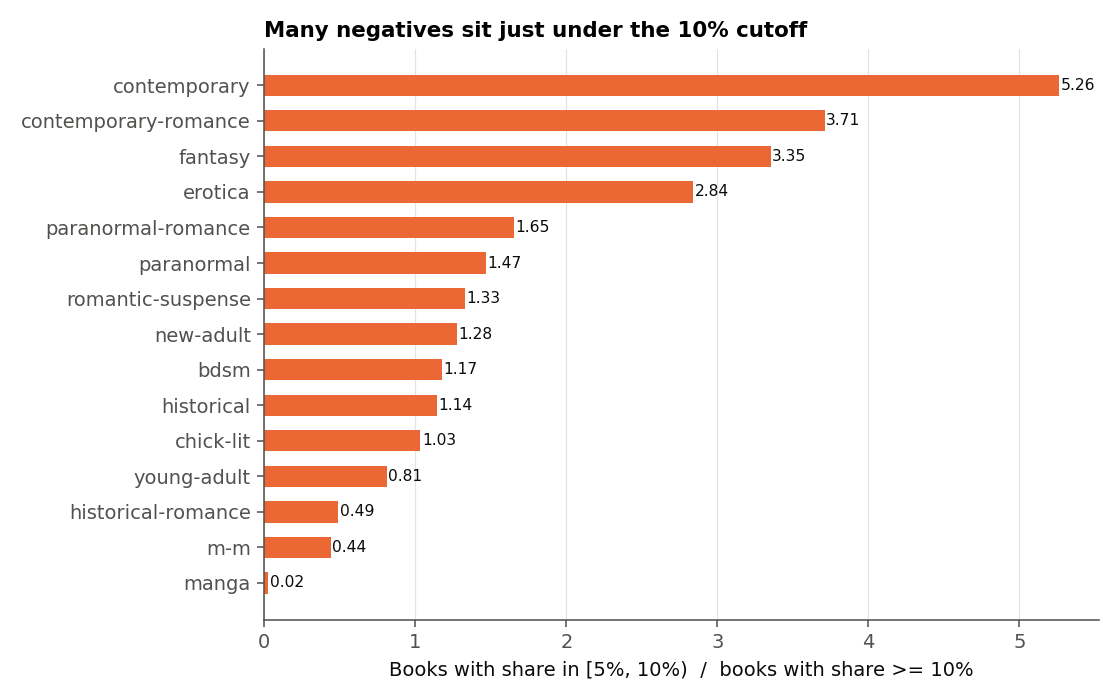

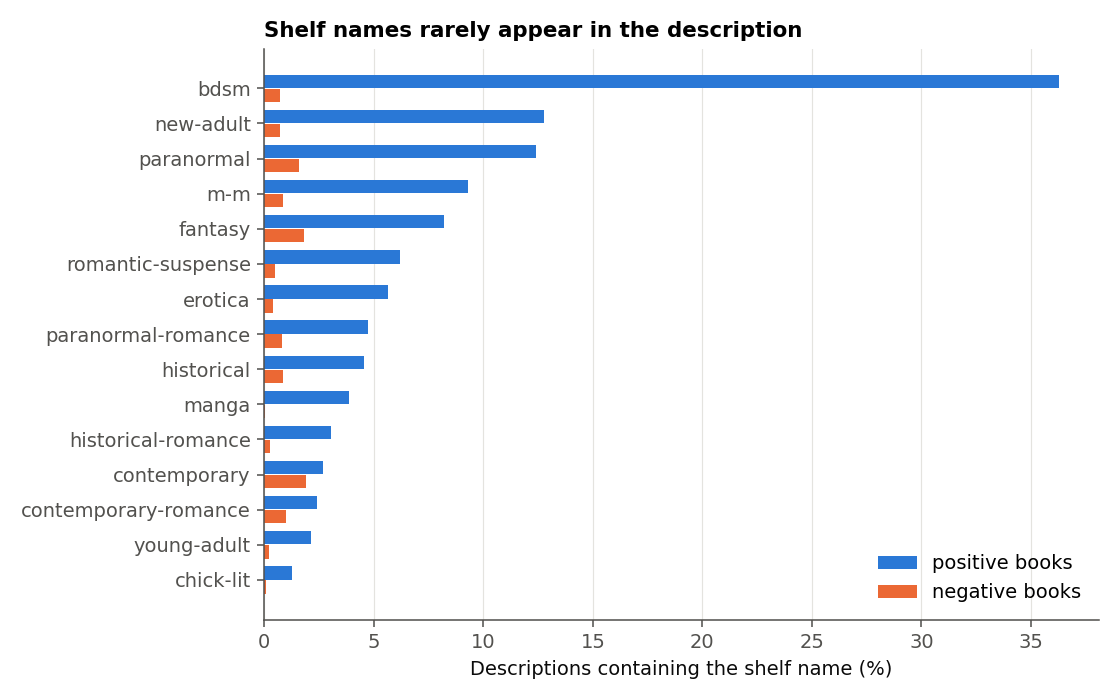

In [1]:
near = pd.read_csv(EDA + 'near_threshold.csv')
f1 = pd.read_csv('reports/full/per_label_wordchar_lr_C1.csv')[['shelf', 'f1', 'auc', 'test_positives']]
kw = pd.read_csv(EDA + 'keyword_in_description.csv')
table = near.merge(kw, on='shelf').merge(f1, on='shelf').sort_values('near_miss_to_positive')
print(table[['shelf', 'share_5_to_10pct', 'share_at_least_10pct', 'near_miss_to_positive',
             'positive_rate', 'f1']].to_string(index=False, float_format='{:.3f}'.format))
rho, p = spearmanr(table.near_miss_to_positive, table.f1)
print(f'\nSpearman, near-miss ratio vs test F1:      rho = {rho:+.2f} (p = {p:.1e}, 15 shelves)')
rho, p = spearmanr(table.test_positives, table.f1)
print(f'Spearman, test positives vs test F1:        rho = {rho:+.2f} (p = {p:.2f})')
rho, p = spearmanr(table.positive_rate, table.f1)
print(f'Spearman, shelf name in positive text vs F1: rho = {rho:+.2f} (p = {p:.2f})')
display(Image(EDA + 'near_threshold.png'))
display(Image(EDA + 'keyword_in_description.png'))

### 2.5 Metadata the model does not use

These fields describe the collection, not the task. Publication year is missing for 30% of raw books, and the remaining values include placeholder years: one book in year 1, two in year 65535, 83 before 1800 and 255 after the 2017 crawl. The plot shows 1950-2017 only, and its median is 2013. Rating counts are heavy-tailed: median 52, mean 448, maximum about 2.08 million, and 1,499 books with no ratings at all. 84% of `similar_books` links point to another book in this file, so a link-prediction task would have been possible; this project does not use it.

missing or empty, of 335,449 raw books
  publication_year    101,800   30.3%
  ratings_count             0    0.0%
  average_rating            0    0.0%
  num_pages           136,630   40.7%
  language_code       104,396   31.1%
  publisher           123,837   36.9%
  format              112,865   33.6%
  is_ebook                  0    0.0%
  isbn                203,238   60.6%
  series              126,503   37.7%
  similar_books       127,924   38.1%
publication_year: median 2013 | year 1: 1 | year 65535: 2 | before 1800: 83 | after 2017: 255
ratings_count: zero 1,499, median 52, mean 448, p99 5,764, max 2,078,406
similar_books links pointing inside this file: 83.8%


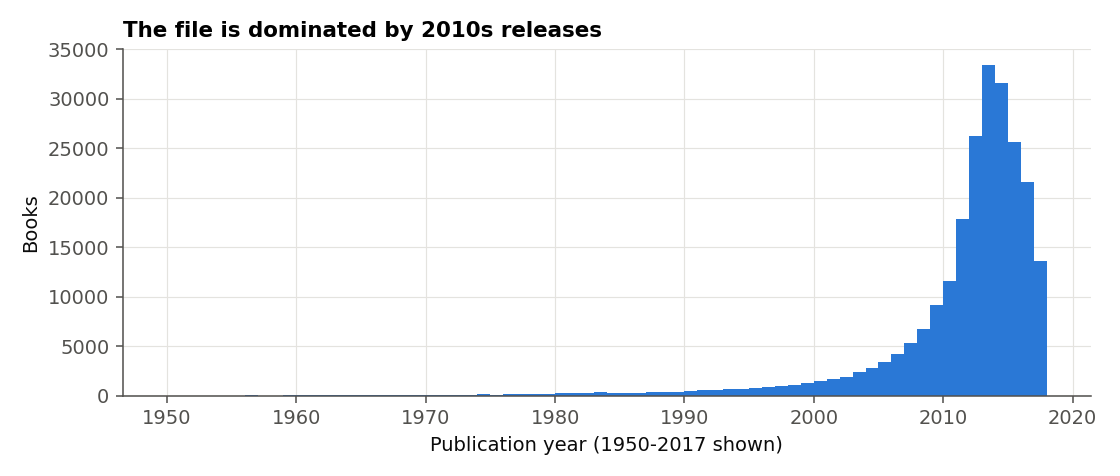

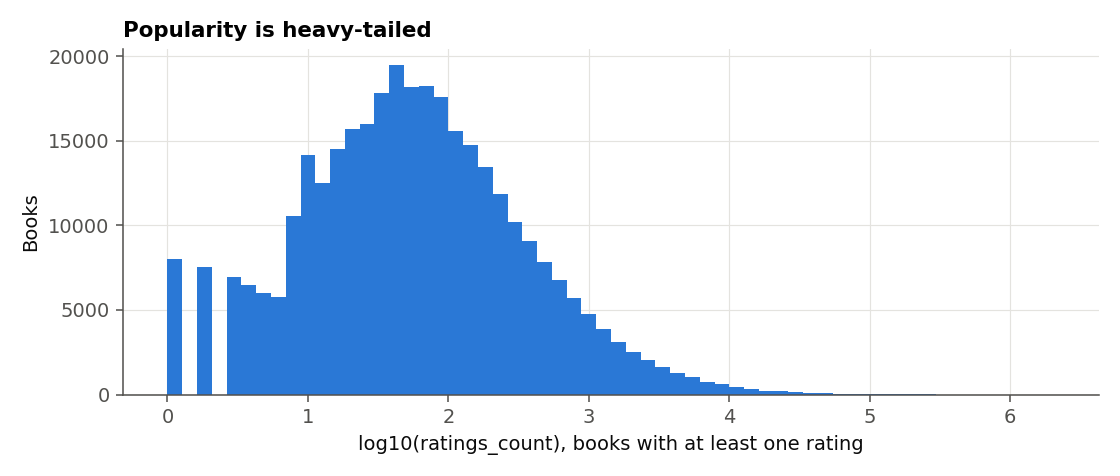

In [1]:
m = stats['raw_missing_or_empty']
print('missing or empty, of', f"{stats['flow']['Raw books']:,}", 'raw books')
for k, n in m.items():
    print(f'  {k:18s}{n:>9,}  {n / stats["flow"]["Raw books"]:6.1%}')
y, r = stats['publication_year'], stats['ratings_count']
print('publication_year: median', int(y['median_valid']), '| year 1:', y['equal_to_1'],
      '| year 65535:', y['equal_to_65535'], '| before 1800:', y['before_1800'],
      '| after 2017:', y['after_2017'])
print(f"ratings_count: zero {r['zero']:,}, median {r['median']:.0f}, mean {r['mean']:.0f},"
      f" p99 {r['p99']:,.0f}, max {r['max']:,.0f}")
print(f"similar_books links pointing inside this file: {stats['similar_books']['inside_share']:.1%}")
display(Image(EDA + 'publication_years.png'))
display(Image(EDA + 'ratings_tail.png'))

### 2.6 What the data implies for modeling

- **Sparse, multi-label targets.** Use one binary classifier per shelf, class weights, per-shelf thresholds, and F1/AP rather than accuracy.
- **Group the split by work.** Most repeated text is editions of the same work; splitting by `book_id` would leak descriptions into test.
- **Expect a ceiling on noisy shelves.** `contemporary`, `contemporary-romance`, `fantasy` and `erotica` have many books just under the 10% line, so some of their "errors" are label noise rather than model failures.
- **Overlapping labels.** Report the 15-label task as defined, and treat the alias merge as a separate sensitivity check.
- **Text only.** Year, ratings and language are incomplete or noisy and are not used, so the comparison stays a description-only task.

## 3. Modeling

Each description is a bag of word and character n-grams. Shelves do not enter the vectorizer. They are only the targets. `work_id` is used only to keep editions together. The model is one logistic regression per shelf (`OneVsRestClassifier`), with `C=1` and balanced class weights. Balancing matters because every shelf is rare. The decision score is a linear function of TF-IDF features. It is not a calibrated probability.

Eight configurations were fit: word versus word-plus-character TF-IDF, two values of `C`, class weighting on or off, and logistic regression versus a linear SVM where that comparison was run. The full grid and timings are in `reports/full/validation_search.csv` and in `modeling/run.py`. Selection used validation macro-F1 with per-label thresholds. The winner is `wordchar_lr_C1`. Its validation macro-F1 is 0.487. The same model's global threshold scores higher validation micro-F1 and lower macro-F1, so the operating point depends on which F1 the project promised to optimize. Thresholds are chosen on validation only. The model is not refit on training plus validation, because a refit would move the scores relative to those thresholds.

Character n-grams help shelves whose cue is a pronoun or a name fragment (`her`, `his`, pieces of Japanese names). Word bigrams help series titles such as `lucky harbor`. A linear model is the right comparison point for this course: it is fast on 191,692 documents, the weights can be read, and it is a standard text-classification baseline. Its limit is that it cannot tell "a manga adaptation whose blurb retells the prose novel" from a prose novel, and it treats `contemporary` and `contemporary-romance` as unrelated outputs even when the blurbs share the same series name.

The original `code.py` exploration used a two-way split and a default threshold. Those older F1 numbers are not the ones in the test table below. The pipeline here keeps that file unchanged and adds a validation cut.


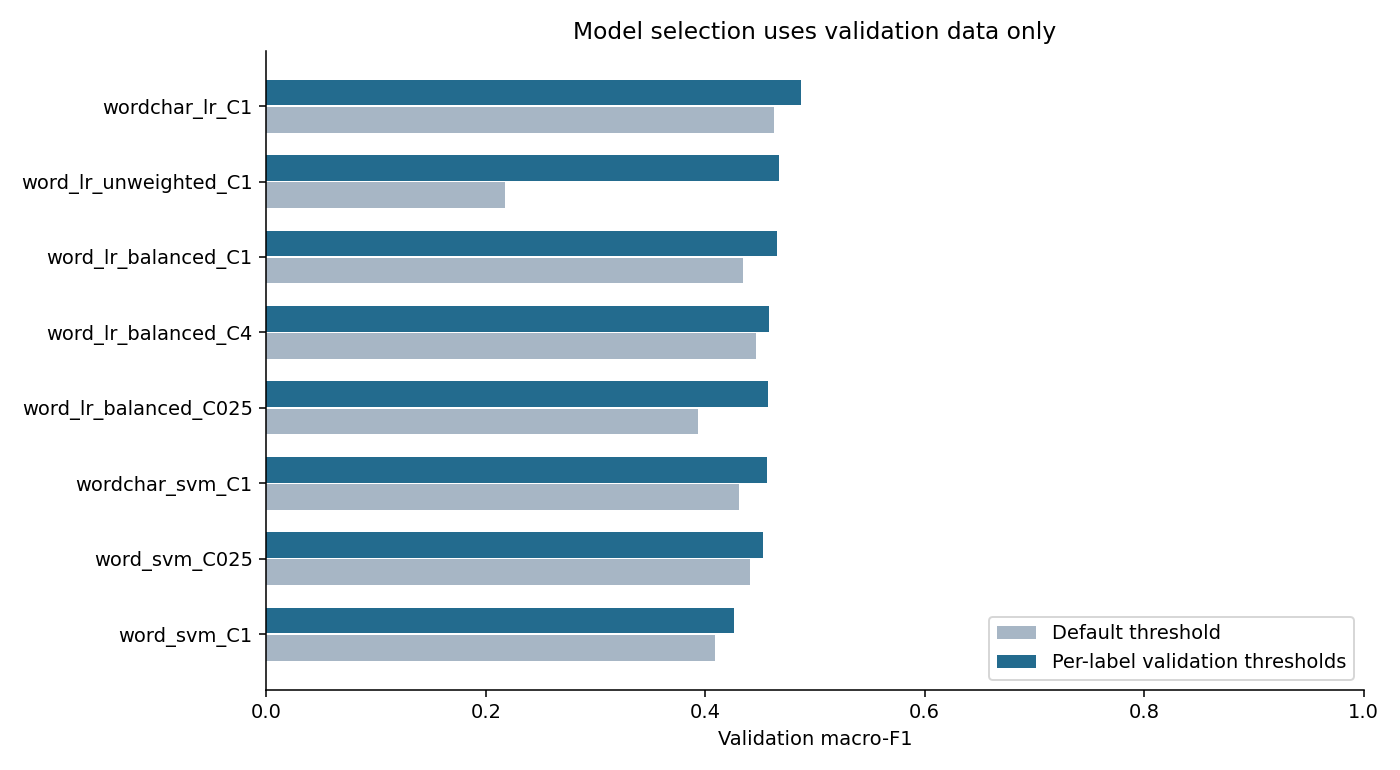

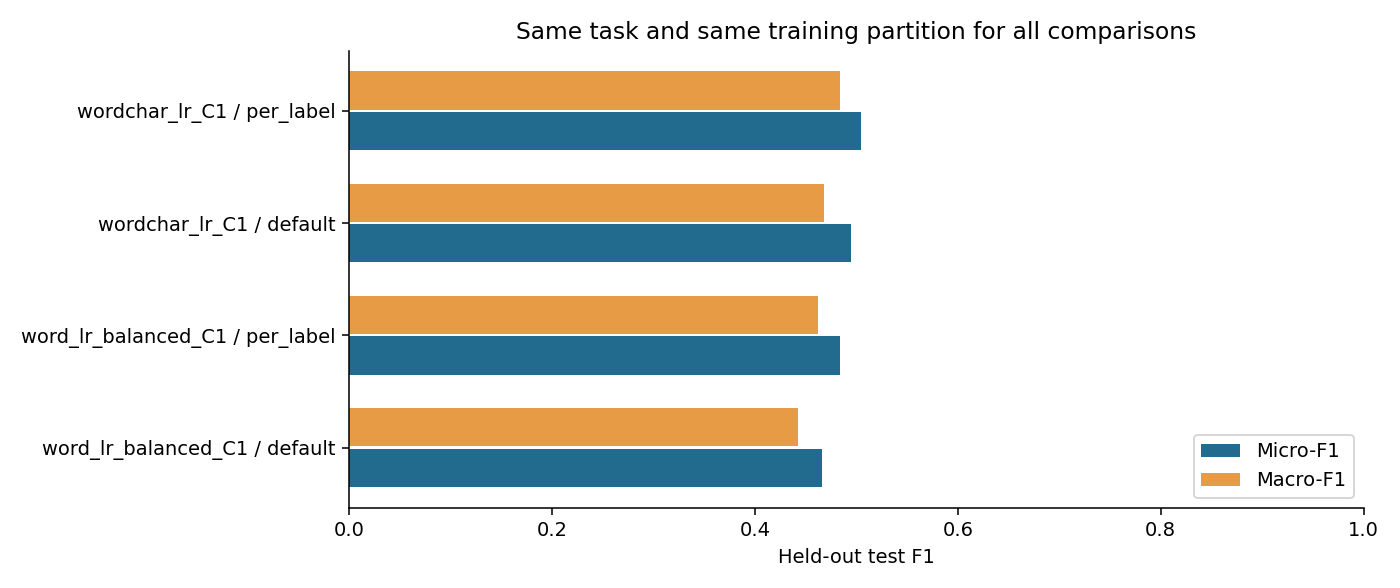

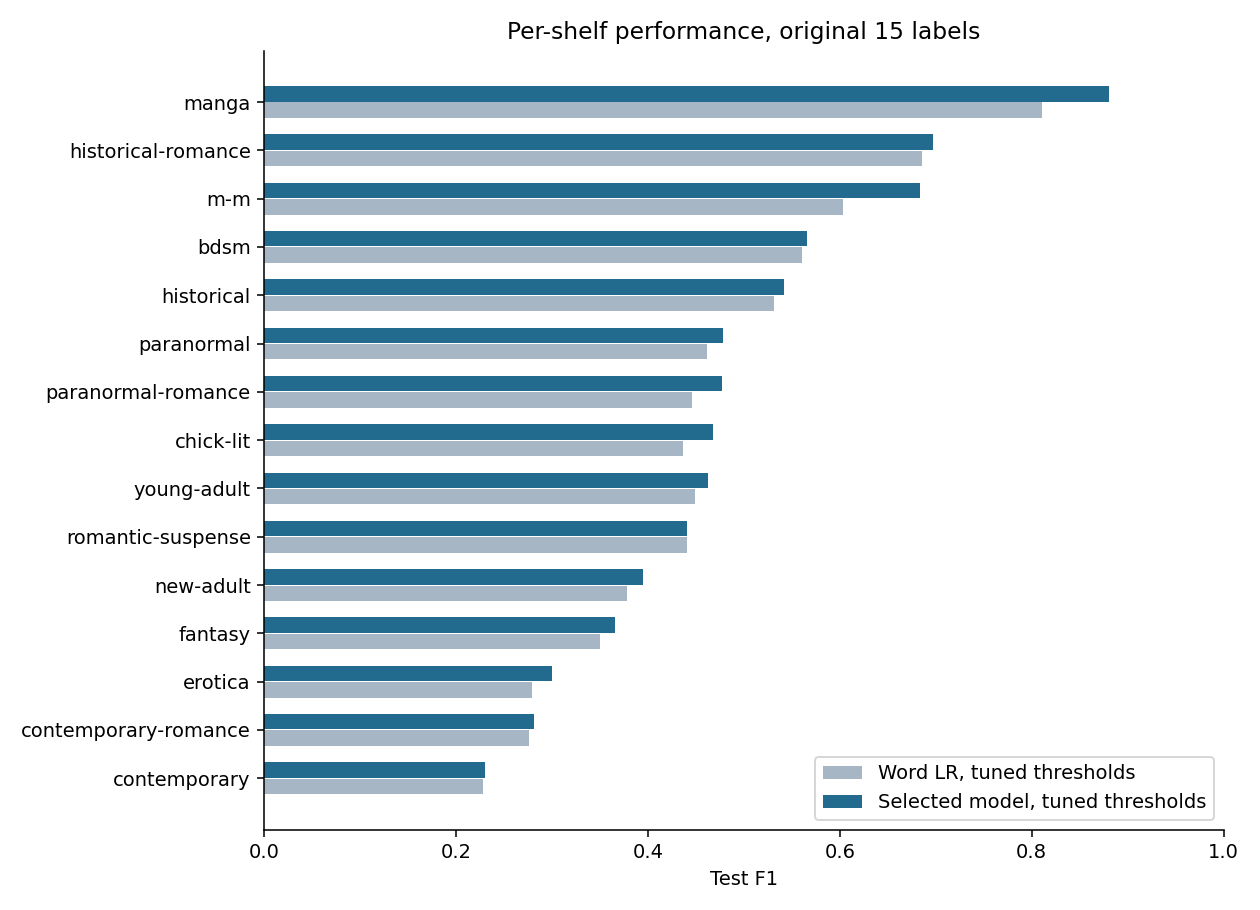

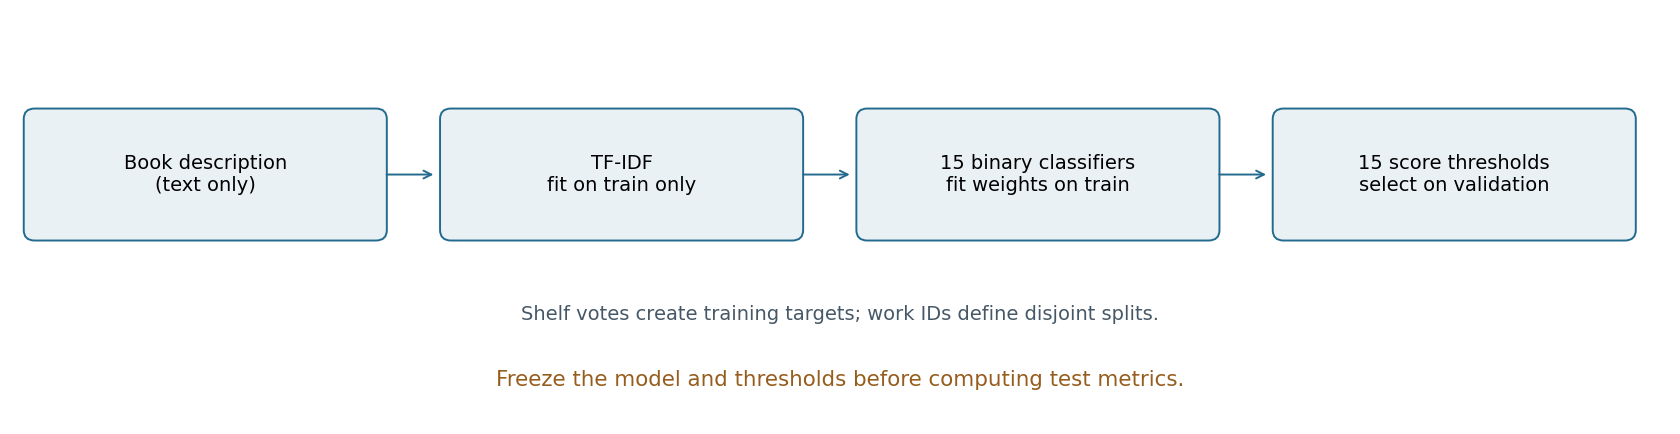

In [1]:
from IPython.display import Image, display
display(Image('reports/full/figures/validation_search.png'))
display(Image('reports/full/figures/test_ablation.png'))
display(Image('reports/full/figures/per_shelf_f1.png'))
display(Image('reports/full/figures/modeling_pipeline.png'))

## 4. Evaluation

### Why these metrics

Micro-F1 pools every book-shelf decision, so `m-m` and `historical-romance` dominate it. Macro-F1 averages the 15 shelves, which is why `contemporary` at F1 0.23 pulls the headline down. Model selection therefore used validation macro-F1. ROC-AUC measures ranking and does not change when the threshold moves: the primary model and its global-threshold variant share macro-AUC 0.9344. Average precision is 0.440. The gap between AUC and average precision is the sparse-positive problem. The scores order books well, and a high rank is still full of false positives. The prior baseline makes the accuracy point concrete. Predicting a label only when its training rate is at least one half yields F1 0, because no shelf is that common.

### Test comparison

The rows below are the matched test results. The primary row is word-plus-character logistic regression with per-label thresholds. The global-threshold row is a second operating point. It was not selected after seeing the test set. On validation it already had higher micro-F1 and lower macro-F1.

| Configuration | Micro-F1 | Macro-F1 | Macro-AUC | Macro-AP |
| --- | ---: | ---: | ---: | ---: |
| Label prior, positive only if the training rate is at least 0.5 | 0.000 | 0.000 | 0.500 | 0.029 |
| Literal keyword match | 0.108 | 0.106 | 0.536 | 0.051 |
| Word LR, default threshold | 0.466 | 0.443 | 0.929 | 0.415 |
| Word LR, per-label thresholds | 0.484 | 0.463 | 0.929 | 0.415 |
| Word + character LR, per-label thresholds (primary) | 0.505 | 0.484 | 0.934 | 0.440 |
| Word + character LR, global threshold | 0.524 | 0.484 | 0.934 | 0.440 |

The keyword baseline from the original plan is the second row. The primary model raises macro-F1 from 0.106 to 0.484. Against the matched word-only logistic regression with its own tuned thresholds, the gain is about 0.020 micro-F1 and 0.022 macro-F1. A paired bootstrap over test works, conditional on the fitted models, puts that macro-F1 gap between 0.018 and 0.026 (`reports/full/bootstrap.json`, 300 resamples). Removing 279 test books whose exact description also appears in training or validation leaves macro-F1 at 0.484. That check does not remove shared authors or series.

The primary threshold predicts 0.61 labels per test book, with micro-precision 0.433 and micro-recall 0.605. The global threshold predicts 0.50 labels per book and buys precision with recall. Say which goal the threshold serves. This project fixed macro-F1 before looking at the test set.

The 12-label merge, which ORs `historical` with `historical-romance`, `contemporary` with `contemporary-romance`, and `paranormal` with `paranormal-romance`, has test micro-F1 0.532 and macro-F1 0.505. Those numbers describe fewer, broader labels.

### Per shelf

On the primary model, `manga` has F1 0.880 (precision 0.883, recall 0.878), `historical-romance` 0.697, and `m-m` 0.683. `contemporary` has F1 0.231 and `contemporary-romance` 0.281. Those two also have the weakest ranking: ROC-AUC 0.827 and 0.849. The other thirteen shelves are all above 0.91 AUC. Lowering the `contemporary` threshold below zero, to −0.44, still leaves precision at 0.158. The shelf is hard to rank, not just hard to threshold.

The strong shelves have a repeated vocabulary. `manga` weights the word `manga` and Japanese name fragments. `historical-romance` weights `lady`, `earl`, `duke`, and `London`. `m-m` weights `his` and `gay`, and puts a large negative weight on `her`. The weak shelves' largest positive weights are series names: `lucky harbor`, `virgin river`, `idaho`. A linear model that memorizes an imprint will miss a standalone Harlequin whose blurb never uses those names.

On the training books the alias pairs are not duplicate names for one set of books. `historical` co-occurs with `historical-romance` on 6,467 books and appears alone on 1,032. `contemporary` and `contemporary-romance` co-occur on 2,272 books, while 3,143 have only the `-romance` name and 2,859 have only `contemporary`. Merging them changes the question.

### Ten mistakes, read against the description

`reports/full/error_review_queue.csv` stores up to three confidence-ranked false positives and three false negatives per shelf. Confidence means a score far above the threshold, or far below it. It is not a random sample of errors. Ten of those rows were read from the raw file. Shelf fractions were recomputed with the same exclusion list. The notes are in `reports/manual_error_analysis.csv`.

Four patterns show up.

**The words match the shelf, and the exact name misses the 10% rule.** *Mishounen Produce, Vol. 02* is a manga false positive. The blurb is a school story and says the heroine copies "a character in a manga she likes." Readers used `mangas`, `manga-manhwa`, and `shoujo`. The exact shelf `manga` has 0 of 83 content votes. *Boy Meets Boy Meets Boy* is an `m-m` false positive. The blurb says "male/male/male menages," and the votes are split across `m-m`, `mm`, `mmm`, and `menage`, so `m-m` itself is 7.2%. *Confessions of a Viscount* is a historical-romance false positive at 9 of 95 votes, 9.5%, with a viscount, the ton, and a London rooftop in the blurb.

**A sibling shelf is positive and this name is not.** *Christmas in Lucky Harbor* is a contemporary false positive. `contemporary` is 8.2% of content votes and `contemporary-romance` is 11.9%. `lucky harbor` is a top feature for both. The model is firing the alias.

**The shelf is real and the blurb does not say so.** *Silver* is a manga false negative with `manga` at 36% of content votes. The stored text is an English aristocratic revenge plot and never says manga. *After Hours* is an `m-m` false negative told from Grace's point of view. The blurb asks whom the neighbor is talking to and does not say the partner is a man. `her` and `she` are the largest negative features for `m-m`. *The Notebook* is a chick-lit false negative: 1,454 of 12,548 content votes, 11.6%, while the blurb follows Noah after the Second World War.

**The positive label is a handful of votes on a different plot.** *Dustin's Novel* is a contemporary false negative from 2 of 15 votes. The description calls it the last book of a time-travel trilogy. *Emma: The Wild and Wanton Edition* clears historical-romance by 5 of 49 votes and sells an erotic Austen rewrite. `sexy` is a negative weight for historical-romance. *Lelang Pengantin* has an Indonesian title and an English Harlequin blurb about a Montana rancher. The miss is not a failure to read Indonesian. The positive `contemporary-romance` features are series names this book does not contain.

### What the errors limit

Some false positives are cutoff and alias artifacts. Counting every one of them as a model hallucination overstates the failure. Some false negatives are missing evidence: the description never states the medium or the partner's gender. The contemporary shelves are a real ranking failure, and the manual sample is too small, and too concentrated in the tails, to estimate how often each pattern occurs.


In [1]:
import csv
with open('reports/manual_error_analysis.csv', encoding='utf-8') as f:
    rows = list(csv.DictReader(f))
print(f'{len(rows)} reviewed cases')
for row in rows:
    print(f"{row['shelf']:22} {row['error_type']:15} {row['book_id']:>8}  {row['title']}")

10 reviewed cases
manga                  false_positive   13330144  Mishounen Produce, Vol. 02
manga                  false_negative    6670295  シルバー 1 (Silver #1)
historical-romance     false_positive      87629  Confessions of a Viscount
historical-romance     false_negative   17433645  Emma: The Wild and Wanton Edition
m-m                    false_positive   29497723  Boy Meets Boy Meets Boy (Mad About the Brit Boys, #4)
m-m                    false_negative    1445610  After Hours
contemporary           false_positive   10841305  Christmas in Lucky Harbor (Lucky Harbor, #1-2)
contemporary           false_negative   29909341  Dustin's Novel
contemporary-romance   false_negative    2674675  Lelang Pengantin
chick-lit              false_negative    6950627  The Notebook


## 5. Related work

The dataset page asks users to cite two papers. Both use Goodreads. Neither predicts shelves from a description, so their scores are not a benchmark for the F1 numbers above.

**Wan and McAuley (2018)** study item recommendation when a user leaves several kinds of feedback that form a chain. A later, more explicit action implies the earlier ones. On Goodreads the chain they use is shelve, then read, then rate, then recommend. Their model, chainRec, scores items for a user by respecting that order. The goal is to rank books a user might interact with. Our input is one book's description and our output is a set of shelf names. We never see a user, so we cannot run their model, and a recall number from a recommender is not a micro-F1 on 15 labels.

Mengting Wan and Julian McAuley. 2018. Item Recommendation on Monotonic Behavior Chains. In *Proceedings of the 12th ACM Conference on Recommender Systems (RecSys '18)*. ACM, 86–94. https://doi.org/10.1145/3240323.3240369

**Wan, Misra, Nakashole, and McAuley (2019)** detect spoiler sentences in book reviews. They release sentence-level spoiler marks and a neural tagger. Spoilers are book-specific, vary by user, and tend to fall later in the review. That is a review-text task. Our file does not contain reviews. A spoiler F1 and a shelf F1 answer different questions about the same public crawl.

Mengting Wan, Rishabh Misra, Ndapa Nakashole, and Julian McAuley. 2019. Fine-Grained Spoiler Detection from Large-Scale Review Corpora. In *Proceedings of the 57th Annual Meeting of the Association for Computational Linguistics*. Association for Computational Linguistics, 2605–2610. https://aclanthology.org/P19-1248/

**Wang and Manning (2012)** is the text-classification comparison. They show that linear bags of words and bigrams, with multinomial Naive Bayes or a linear SVM, are strong sentiment and topic classifiers, and that bigrams help. Our model is in that family: TF-IDF word and character n-grams and a linear classifier, here logistic regression because the target is multi-label and the class weights are easy to set. Their paper also says why a linear bag of words fails when the meaning depends on what the blurb leaves out. "Not an inhumane monster" is their example of composition. Our *Silver* and *After Hours* cases are the same kind of miss: the shelf is a fact about the book, and the description never states it. We do not claim their sentiment accuracies as a target. Sentiment on movie reviews is one label per document. We have 15 sparse labels and a 10% vote rule.

Sida Wang and Christopher D. Manning. 2012. Baselines and Bigrams: Simple, Good Sentiment and Topic Classification. In *Proceedings of the 50th Annual Meeting of the Association for Computational Linguistics (Volume 2: Short Papers)*. Association for Computational Linguistics, 90–94. https://aclanthology.org/P12-2018/
